# Morpho-U-Net (White Top-Hat + Distance Transform) on fixed 592x592 -- plain backbone

This notebook tests a specific architecture recommendation made after reviewing every
fixed-592 experiment run in this project: **graft the parameter-free morphological
preprocessing (`MorphoPreprocessor`: white top-hat + distance-transform) onto the plain,
full-capacity U-Net backbone** (the same `DoubleConv`/64->1024-channel design as
[`unet/Unet_images_only.ipynb`](../unet/Unet_images_only.ipynb), which already holds the
best result in this repo at 0.8023 mean vessel Dice) -- **not** onto the BiFPN-neck
backbone.

## Why this combination specifically

Every technique tried in this project so far, evaluated at fixed 592x592:

| Model | Mean Vessel Dice |
|---|---|
| Standard U-Net (plain backbone, RGB only) | **0.8023** |
| BiFPN-UNet (BiFPN neck, RGB only) | 0.7906 |
| MorphoBiFPN-UNet (BiFPN neck + TopHat/DistTransform) | 0.7863 |
| Seg+Class two-stage pipeline (both variants) | 0.66-0.71 |

The pattern is consistent: **every addition on top of the plain backbone underperformed
the plain backbone itself**, on this 70-image training set. That includes the BiFPN neck
itself (0.7906 < 0.8023) -- so MorphoBiFPN-UNet's small additional drop (0.7863) likely
reflects the BiFPN neck's capacity/overfitting tax, not a problem with the morpho features
themselves. `MorphoPreprocessor` has **zero learnable parameters** (a fixed Gaussian blur
buffer and a plain float threshold) -- it cannot itself cause overfitting -- so isolating
it onto the *one* backbone that has actually proven not to overfit on this dataset (the
plain U-Net, trained for a full 150 epochs with no early stopping needed in its own
notebook) is the most promising untested combination for beating 0.8023.

## What this notebook does differently from the closest existing notebooks

* Reuses the **exact `MorphoPreprocessor` + `MorphoUNet` architecture** already defined in
  [`morpho/Morpho_Unet_TopHat_DistanceTransform_images_only.ipynb`](Morpho_Unet_TopHat_DistanceTransform_images_only.ipynb)
  (64->1024 channel U-Net, in_channels=3, encoder receives `[raw, tophat, dist]` = 9
  channels) -- but that notebook trains on **native resolution + zero-padding**. This one
  retrains it on a **fixed 592x592 resize**, matching `Unet_images_only.ipynb`'s convention
  (the single biggest lever for Dice found in this whole project).
* Reuses the **dataset, loss (`CEDiceLoss`), optimizer (`AdamW`), schedule
  (`CosineAnnealingLR`), and crash-safe training loop** from
  [`morpho_BiFPN/MorphoBiFPN_Unet_TopHat_DistanceTransform_Fixed592.ipynb`](../morpho_BiFPN/MorphoBiFPN_Unet_TopHat_DistanceTransform_Fixed592.ipynb)
  verbatim -- the only change from that notebook is the model class itself (`MorphoUNet`,
  plain skip-connections, 64->1024 channels) in place of `MorphoBiFPNUNet` (BiFPN neck,
  32->256 channels).
* Profiling confirmed this larger architecture (31M params vs. ~2-5M for the lean BiFPN
  recipes) still trains in **~20 minutes for 150 epochs** at `batch_size=4` on this GPU, so
  early stopping (`patience_evals=10`) is kept as a safety net but the full capacity is not
  reduced to compensate -- the plain U-Net at this same capacity already proved it doesn't
  need that compensation.

## Imports

In [1]:
import os
import copy
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.transforms as T

print("All imports successful.")


All imports successful.


## Multiclass Constants

In [2]:
NUM_CLASSES   = 3
CLASS_NAMES   = {0: 'Background', 1: 'Artery', 2: 'Vein'}
CLASS_COLORS  = {
    0: np.array([  0,   0,   0], dtype=np.uint8),  # Background : black
    1: np.array([255,   0,   0], dtype=np.uint8),  # Artery     : red
    2: np.array([  0,   0, 255], dtype=np.uint8),  # Vein       : blue
}
VESSEL_CLASSES = [1, 2]   # classes used for mean Dice (exclude background)

print(f"Multiclass segmentation: {NUM_CLASSES} classes")
for k, v in CLASS_NAMES.items():
    print(f"  {k} = {v}")


Multiclass segmentation: 3 classes
  0 = Background
  1 = Artery
  2 = Vein


## Dataset Class

Loads PNG fundus images and RGB annotation maps. Every image and its annotation are
**resized to a fixed `(new_size, new_size)` canvas** (RGB via `BILINEAR`, annotation via
`NEAREST` to keep class boundaries crisp) -- identical to
`morpho_BiFPN/MorphoBiFPN_Unet_TopHat_DistanceTransform_Fixed592.ipynb`'s dataset.

In [3]:
class ImageDataset(data.Dataset):
    """
    Multiclass retinal AV segmentation dataset using RGB images only, resized to a
    fixed (new_size x new_size) canvas.

    Expected layout per split root:
        <root>/
            images/       *.png           (fundus images, RGB)
            annotation/   *.png           (RGB multiclass label maps)

    Label colour -> class index:
        black  (0,0,0)       -> 0  background
        red    (255,0,0)     -> 1  artery
        blue   (0,0,255)     -> 2  vein
        green  (0,255,0)     -> 3  crossing    (remapped to 0)
        white  (255,255,255) -> 4  uncertainty (remapped to 0)
    """

    def __init__(self, root, new_size=592, supervised=True, augment=False):
        self.root       = Path(root)
        self.supervised = supervised
        self.new_size   = new_size
        self.augment    = augment

        img_dir = self.root / 'images'
        ann_dir = self.root / 'annotation'

        self.image_paths = sorted(img_dir.glob('*.png'))
        self.label_paths = []

        if self.supervised:
            for img_path in self.image_paths:
                stem = img_path.stem
                self.label_paths.append(ann_dir / f'{stem}.png')

        print(f"Dataset root        : {root}")
        print(f"  Images found      : {len(self.image_paths)}")
        if self.supervised:
            print(f"  Annotations found : {len(self.label_paths)}")
        print(f"  Augmentation      : {self.augment}")
        if self.image_paths:
            print(f"  First 5 images    : {[p.name for p in self.image_paths[:5]]}")

    @staticmethod
    def rgb_to_class_mask(rgb_array):
        """
        Convert an RGB annotation array (H, W, 3) to an integer class mask (H, W).

        Crossing (green) and Uncertainty (white) pixels are remapped to
        Background (0) -- only 3 classes are used.
        """
        r, g, b = rgb_array[:, :, 0], rgb_array[:, :, 1], rgb_array[:, :, 2]
        mask = np.zeros(rgb_array.shape[:2], dtype=np.int64)
        mask[(r > 180) & (g < 80)  & (b < 80)]  = 1   # Artery
        mask[(r < 80)  & (g < 80)  & (b > 180)] = 2   # Vein
        return mask

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        s = self.new_size

        image = Image.open(self.image_paths[index]).convert('RGB').resize((s, s), Image.BILINEAR)

        if not self.supervised:
            return T.ToTensor()(image)

        ann_rgb_img = Image.open(self.label_paths[index]).convert('RGB').resize((s, s), Image.NEAREST)

        if self.augment:
            if random.random() < 0.5:
                image       = image.transpose(Image.FLIP_LEFT_RIGHT)
                ann_rgb_img = ann_rgb_img.transpose(Image.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                image       = image.transpose(Image.FLIP_TOP_BOTTOM)
                ann_rgb_img = ann_rgb_img.transpose(Image.FLIP_TOP_BOTTOM)
            angle = random.uniform(-10, 10)
            image       = image.rotate(angle, resample=Image.BILINEAR, fillcolor=(0, 0, 0))
            ann_rgb_img = ann_rgb_img.rotate(angle, resample=Image.NEAREST, fillcolor=(0, 0, 0))

        image_t = T.ToTensor()(image)                                  # (3, s, s)
        mask    = self.rgb_to_class_mask(np.array(ann_rgb_img))        # (s, s) int64
        label   = torch.from_numpy(mask)                               # LongTensor (s, s)
        return image_t, label


## Load Data

Dataset root        : /home/mefeki/Bureau/work/Fundus-AVSeg-prep-data/test
  Images found      : 20
  Annotations found : 20
  Augmentation      : False
  First 5 images    : ['081_D.png', '082_N.png', '083_G.png', '084_D.png', '085_N.png']
Dataset sizes: {'test': 20}


Image shape     : torch.Size([1, 3, 592, 592])
Label shape     : torch.Size([1, 592, 592])   dtype: torch.int64


Unique classes  : [0, 1, 2]


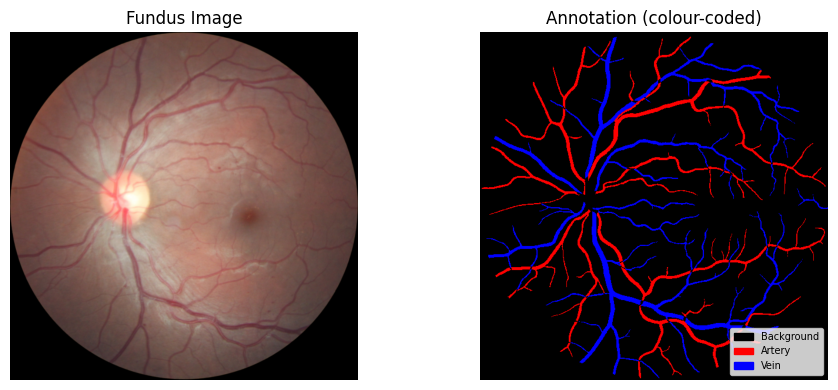

In [4]:
root = r"/home/mefeki/Bureau/work/Fundus-AVSeg-prep-data"

test_dataset    = ImageDataset(root=os.path.join(root, 'test'), augment=False)
train_root      = os.path.join(root, 'train')

test_dataloader = data.DataLoader(test_dataset, shuffle=False, batch_size=1)

print("Dataset sizes:", {'test': len(test_dataset)})

# -- Quick sanity-check visualisation -----------------------------------------------
it = iter(data.DataLoader(test_dataset, shuffle=False, batch_size=1))
inputs, labels = next(it)

print("Image shape     :", inputs.shape)
print("Label shape     :", labels.shape, "  dtype:", labels.dtype)
print("Unique classes  :", labels.unique().tolist())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

out_inputs = torchvision.utils.make_grid(inputs)
axes[0].imshow(out_inputs.permute(1, 2, 0).clamp(0, 1))
axes[0].set_title('Fundus Image')
axes[0].axis('off')

lbl_np  = labels[0].numpy()
lbl_rgb = np.zeros((*lbl_np.shape, 3), dtype=np.uint8)
for cls_idx, color in CLASS_COLORS.items():
    lbl_rgb[lbl_np == cls_idx] = color
axes[1].imshow(lbl_rgb)
axes[1].set_title('Annotation (colour-coded)')
axes[1].axis('off')

legend_handles = [
    Patch(color=np.array(c)/255, label=n)
    for c, n in zip(CLASS_COLORS.values(), CLASS_NAMES.values())
]
axes[1].legend(handles=legend_handles, loc='lower right', fontsize=7)

fig.tight_layout()
plt.show()


## Colour-Map Utility

In [5]:
def class_to_rgb(mask_np):
    """Convert an integer class mask (H, W) to a colour-coded RGB image (H, W, 3)."""
    rgb = np.zeros((*mask_np.shape, 3), dtype=np.uint8)
    for cls_idx, color in CLASS_COLORS.items():
        rgb[mask_np == cls_idx] = color
    return rgb

## Morphological Preprocessing: White Top-Hat & Distance Transform

`MorphoPreprocessor` has **no learnable parameters**: `gauss` is a fixed (non-trainable)
buffer, and `threshold` is a plain float, not an `nn.Parameter`. Every output pixel is a
deterministic function of the corresponding input pixel's local neighbourhood, so this
block adds feature richness without adding model capacity or overfitting risk. Copied
verbatim from
[`Morpho_Unet_TopHat_DistanceTransform_images_only.ipynb`](Morpho_Unet_TopHat_DistanceTransform_images_only.ipynb).

In [6]:
class MorphoPreprocessor(nn.Module):
    """
    Differentiable morphological preprocessing block computing a white top-hat and an
    iterative-erosion distance-transform approximation, depth-wise over every input
    channel.

    Args
    ----
    in_channels  : number of input feature channels (applied depth-wise).
    gauss_kernel : side length of the square Gaussian kernel (odd int).
    gauss_sigma  : standard deviation of the Gaussian kernel.
    morph_kernel : side length of the square structuring element (odd int).
    threshold    : centre of the sigmoid soft-threshold used before the distance-transform
                   step.
    dist_iters   : number of erosion steps accumulated for the distance-transform
                   approximation.
    """
    def __init__(self, in_channels, gauss_kernel=5, gauss_sigma=1.0,
                 morph_kernel=3, threshold=0.47, dist_iters=10):
        super().__init__()
        self.in_channels = in_channels
        self.morph_kernel = morph_kernel
        self.morph_pad = morph_kernel // 2
        self.threshold = threshold
        self.dist_iters = dist_iters
        self.gauss_pad = gauss_kernel // 2

        gauss = self._make_gaussian_kernel(gauss_kernel, gauss_sigma)
        self.register_buffer('gauss', gauss.expand(in_channels, 1, -1, -1).contiguous())

    @staticmethod
    def _make_gaussian_kernel(k, sigma):
        ax = torch.linspace(-(k - 1) / 2., (k - 1) / 2., k)
        xx, yy = torch.meshgrid(ax, ax, indexing='ij')
        kernel = torch.exp(-0.5 * (xx ** 2 + yy ** 2) / sigma ** 2)
        return (kernel / kernel.sum()).view(1, 1, k, k)

    def _dilate(self, x):
        """Morphological dilation via max-pool."""
        return F.max_pool2d(x, self.morph_kernel, stride=1, padding=self.morph_pad)

    def _erode(self, x):
        """Morphological erosion via negated max-pool."""
        return -F.max_pool2d(-x, self.morph_kernel, stride=1, padding=self.morph_pad)

    def _opening(self, x):
        """Morphological opening: erosion followed by dilation."""
        return self._dilate(self._erode(x))

    def _white_tophat(self, x):
        """White top-hat: x minus its morphological opening."""
        return torch.clamp(x - self._opening(x), min=0.0)

    def _distance_transform(self, mask):
        """Iterative-erosion approximation of the distance transform."""
        dist = torch.zeros_like(mask)
        current = mask
        for _ in range(self.dist_iters):
            current = self._erode(current)
            dist = dist + current
        return dist / self.dist_iters

    def forward(self, x):
        blurred = F.conv2d(x, self.gauss, padding=self.gauss_pad, groups=self.in_channels)
        tophat = self._white_tophat(blurred)
        soft_mask = torch.sigmoid(20.0 * (blurred - self.threshold))
        dist = self._distance_transform(soft_mask)
        return tophat, dist


## Morpho-U-Net Architecture (plain backbone, no BiFPN)

Standard U-Net encoder/decoder (`DoubleConv`/`Down`/`Up`, 64->1024 channels -- the same
capacity as `unet/Unet_images_only.ipynb`'s `StandardUNet`) whose input is
`[raw, white_tophat(raw), distance_transform(raw)]` via `MorphoPreprocessor` above, instead
of raw RGB alone. No BiFPN neck, no learned fusion weights -- plain skip connections, the
one backbone in this project proven not to overfit on this 70-image training set.

In [7]:
class DoubleConv(nn.Module):
    """Two 3x3 convolutions (padding=1), batch normalization and ReLU."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.doubleconv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.doubleconv(x)


class Down(nn.Module):
    """2x2 max pooling, then double convolution."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.downconv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.downconv(x)


class Up(nn.Module):
    """Transposed-conv upsampling, then double convolution.

    Resizes the upsampled tensor to the skip connection's spatial size when
    they differ."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        if x1.shape[-2:] != x2.shape[-2:]:
            x1 = F.interpolate(x1, size=x2.shape[-2:], mode='bilinear', align_corners=False)
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


class MorphoUNet(nn.Module):
    """
    Morpho-U-Net: standard U-Net with an integrated morphological
    preprocessing block computing white top-hat and a distance-transform
    approximation in parallel with the raw input.

    The preprocessor's two outputs (same spatial size and channel count as x)
    are concatenated with the raw input along the channel axis, so the
    encoder receives `3 * in_channels` channels: raw signal, white top-hat,
    and distance transform.
    """

    def __init__(self, in_channels, n_classes, gauss_kernel=5, gauss_sigma=1.0,
                 morph_kernel=3, threshold=0.47, dist_iters=10):
        super().__init__()

        self.preprocessor = MorphoPreprocessor(
            in_channels, gauss_kernel, gauss_sigma, morph_kernel, threshold, dist_iters
        )

        enc_in = in_channels * 3   # raw + white-tophat + distance-transform

        self.inc   = DoubleConv(enc_in, 64)
        self.down1 = Down(64,   128)
        self.down2 = Down(128,  256)
        self.down3 = Down(256,  512)
        self.down4 = Down(512, 1024)

        self.up1 = Up(1024, 512)
        self.up2 = Up(512,  256)
        self.up3 = Up(256,  128)
        self.up4 = Up(128,   64)

        self.out = nn.Conv2d(64, n_classes, kernel_size=1)

    def forward(self, x):
        tophat, dist = self.preprocessor(x)
        x_in = torch.cat([x, tophat, dist], dim=1)    # (B, 3C, H, W)

        x1 = self.inc(x_in)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x  = self.up1(x5, x4)
        x  = self.up2(x,  x3)
        x  = self.up3(x,  x2)
        x  = self.up4(x,  x1)

        return self.out(x)


## Loss: Weighted Cross-Entropy + Soft Dice

Identical to `morpho_BiFPN/MorphoBiFPN_Unet_TopHat_DistanceTransform_Fixed592.ipynb`'s
`CEDiceLoss` (and the plain `BiFPN_Unet_Fixed592.ipynb`'s) -- the recipe already validated
not to overfit catastrophically on this dataset at fixed-592.

In [8]:
class SoftDiceLoss(nn.Module):
    """Soft Dice loss on softmax probabilities, averaged over `classes`."""
    def __init__(self, classes=VESSEL_CLASSES, eps=1e-6):
        super().__init__()
        self.classes = classes
        self.eps     = eps

    def forward(self, logits, labels):
        probs  = torch.softmax(logits, dim=1)
        losses = []
        for c in self.classes:
            p  = probs[:, c]
            t  = (labels == c).float()
            tp = (p * t).sum(dim=(1, 2))
            fp = (p * (1 - t)).sum(dim=(1, 2))
            fn = ((1 - p) * t).sum(dim=(1, 2))
            dice = (2 * tp + self.eps) / (2 * tp + fp + fn + self.eps)
            losses.append((1 - dice).mean())
        return torch.stack(losses).mean()


class CEDiceLoss(nn.Module):
    """Weighted CE (pixel-wise class balance) + Soft Dice (direct Dice-metric proxy)."""
    def __init__(self, class_weights=None, dice_weight=0.5):
        super().__init__()
        self.ce          = nn.CrossEntropyLoss(weight=class_weights)
        self.dice        = SoftDiceLoss()
        self.dice_weight = dice_weight

    def forward(self, logits, labels):
        labels = labels.long()
        return (1 - self.dice_weight) * self.ce(logits, labels) + self.dice_weight * self.dice(logits, labels)

## Evaluation Metrics

In [9]:
def accuracy(preds, labels, eps=1e-6):
    """Overall pixel accuracy."""
    return float(torch.sum(preds == labels)) / (float(labels.numel()) + eps)


def dice_coef_per_class(preds, labels, num_classes=NUM_CLASSES, eps=1e-6):
    """Per-class Dice + mean Dice over VESSEL_CLASSES (excludes background)."""
    per_class = {}
    for c in range(num_classes):
        pred_c  = (preds  == c).float()
        label_c = (labels == c).float()
        tp = float(torch.sum(pred_c  * label_c))
        fp = float(torch.sum(pred_c  * (1 - label_c)))
        fn = float(torch.sum((1 - pred_c) * label_c))
        per_class[c] = 2 * tp / (2 * tp + fp + fn + eps)
    mean_vessel_dice = float(np.mean([per_class[c] for c in VESSEL_CLASSES]))
    return per_class, mean_vessel_dice

## Training & Test Functions

`train_model` extends the pattern used by every other Fixed592 notebook in this project:
crash-safe checkpoint saving (`torch.save` on every new best) plus CSV history logging, and
early stopping (`patience_evals`) as a safety net for this larger architecture.

In [10]:
def test_model(model, dataloader, verbose=True):
    model.eval()
    total_dice = 0.0
    n = 0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            logits = model(inputs)
            probs  = torch.softmax(logits, dim=1)
            preds  = torch.argmax(probs, dim=1)

            _, vessel_dice = dice_coef_per_class(preds, labels)
            total_dice += vessel_dice
            n += 1

    final_dice = total_dice / max(n, 1)
    if verbose:
        print(f'\nMean vessel Dice on test set: {final_dice:.4f}')
    return final_dice


def train_model(model, criterion, optimizer, scheduler, train_loader, test_loader,
                 num_epochs, eval_every=5,
                 checkpoint_path='models/best_model_morpho_unet_tophat_dist_592.pth',
                 history_path='training_history_morpho_unet_tophat_dist_592.csv',
                 patience_evals=None):
    best_dice  = -1.0
    best_state = copy.deepcopy(model.state_dict())
    epoch_losses  = []
    eval_history  = []   # list of (epoch, test_dice)
    evals_since_best = 0

    os.makedirs(os.path.dirname(checkpoint_path) or '.', exist_ok=True)
    with open(history_path, 'w') as f:
        f.write('epoch,test_vessel_dice,is_best\n')

    for epoch in range(num_epochs):
        model.train()
        batch_losses = []
        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())

        scheduler.step()
        mean_loss = sum(batch_losses) / len(batch_losses)
        epoch_losses.append(mean_loss)

        is_last = (epoch == num_epochs - 1)
        if (epoch + 1) % eval_every == 0 or is_last:
            dice = test_model(model, test_loader, verbose=False)
            eval_history.append((epoch + 1, dice))
            is_best = dice > best_dice
            if is_best:
                best_dice  = dice
                best_state = copy.deepcopy(model.state_dict())
                torch.save(best_state, checkpoint_path)   # crash-safe: persist immediately
                evals_since_best = 0
            else:
                evals_since_best += 1
            with open(history_path, 'a') as f:
                f.write(f'{epoch + 1},{dice:.6f},{int(is_best)}\n')
            print(f'Epoch {epoch+1}/{num_epochs}  Loss: {mean_loss:.4f}  '
                  f'Test vessel Dice: {dice:.4f}  (best so far: {best_dice:.4f})')

            if patience_evals is not None and evals_since_best >= patience_evals:
                print(f'Early stopping: no improvement in {patience_evals} eval checks '
                      f'({patience_evals * eval_every} epochs).')
                break
        else:
            print(f'Epoch {epoch+1}/{num_epochs}  Loss: {mean_loss:.4f}')

    print('Training complete.')
    model.load_state_dict(best_state)
    return model, epoch_losses, eval_history, best_dice


## Setup Device & Load Full Training Set

In [11]:
import gc
gc.collect()
torch.cuda.empty_cache()


In [12]:
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

train_dataset_full = ImageDataset(root=train_root, supervised=True, augment=True)

print(f"Total training images : {len(train_dataset_full)}")
print('Using full training set (with augmentation). ✓')


Using device: cuda:1
Dataset root        : /home/mefeki/Bureau/work/Fundus-AVSeg-prep-data/train
  Images found      : 70
  Annotations found : 70
  Augmentation      : True
  First 5 images    : ['001_G.png', '002_N.png', '003_N.png', '004_D.png', '005_N.png']
Total training images : 70
Using full training set (with augmentation). ✓


## Training on the Full Training Set (150 epochs, fixed 592x592, plain backbone)


=== Training on full training set (70 images) ===
Dataset root        : /home/mefeki/Bureau/work/Fundus-AVSeg-prep-data/train
  Images found      : 70
  Annotations found : 70
  Augmentation      : False
  First 5 images    : ['001_G.png', '002_N.png', '003_N.png', '004_D.png', '005_N.png']


Class pixel %: {'Background': '91.33%', 'Artery': '3.94%', 'Vein': '4.73%'}
Class weights: tensor([0.0471, 1.0909, 0.9091])


Model parameters: 31,047,107


Epoch 1/150  Loss: 0.9202


Epoch 2/150  Loss: 0.8059


Epoch 3/150  Loss: 0.7321


... (129 outputs left out)

Epoch 133/150  Loss: 0.1417


Epoch 134/150  Loss: 0.1396


Epoch 135/150  Loss: 0.1395  Test vessel Dice: 0.7882  (best so far: 0.7917)
Early stopping: no improvement in 10 eval checks (50 epochs).
Training complete.



Mean vessel Dice on test set: 0.7917

Best test vessel Dice during training       : 0.7917 (best-of-training selection)
Final-epoch test vessel Dice (epoch 135)       : 0.7882 (no selection -- fairer vs. baseline)
Standard U-Net (RGB, 592x592) baseline       : 0.8023
Plain BiFPN-UNet (RGB, 592x592)               : 0.7906
MorphoBiFPN-UNet (TopHat+Dist, BiFPN neck)    : 0.7863
Does not beat the baseline (best-of-training comparison).
Model already saved to models/best_model_morpho_unet_tophat_dist_592.pth


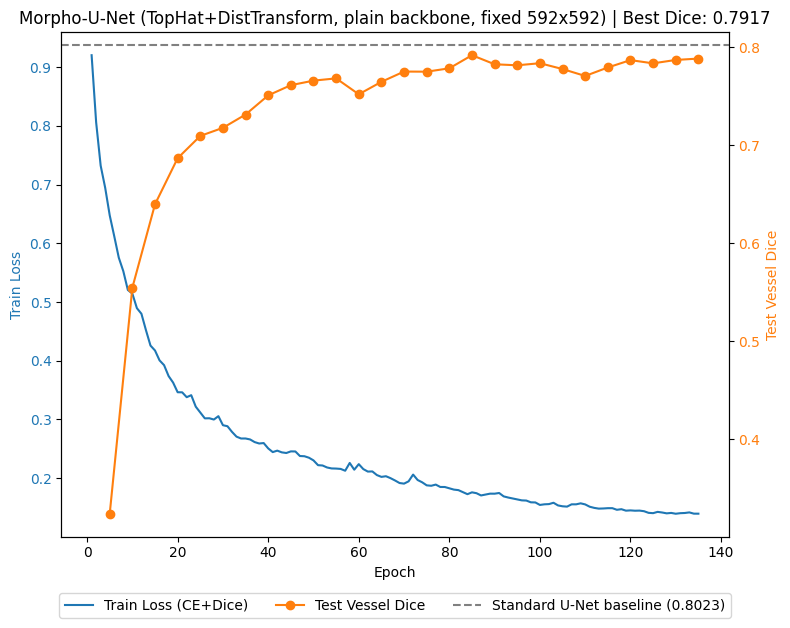

In [13]:
# -- Training hyper-parameters -------------------------------------------------
# Same recipe as morpho_BiFPN/MorphoBiFPN_Unet_TopHat_DistanceTransform_Fixed592.ipynb
# and BiFPN/BiFPN_Unet_Fixed592.ipynb -- already validated not to overfit catastrophically
# on this 70-image training set. patience_evals is kept as a safety net even though this
# architecture has much higher capacity (31M params) than those leaner BiFPN recipes,
# because it matches Standard U-Net's own proven capacity rather than because it is
# expected to be needed.
EPOCHS         = 150
BATCH_SIZE     = 4
SEED           = 42
EVAL_EVERY     = 5
DICE_WEIGHT    = 0.3
PATIENCE_EVALS = 10

full_dataloader = data.DataLoader(
    train_dataset_full, shuffle=True, batch_size=BATCH_SIZE,
    num_workers=4, pin_memory=True, persistent_workers=True)

print(f'\n=== Training on full training set ({len(train_dataset_full)} images) ===')

torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

# -- Class weights (computed over full training set, pre-augmentation pass) -------
pixel_counts = Counter()
plain_dataset_for_weights = ImageDataset(root=train_root, supervised=True, augment=False)
for _, lbl in plain_dataset_for_weights:
    for c in range(NUM_CLASSES):
        pixel_counts[c] += int((lbl == c).sum())

total    = sum(pixel_counts.values())
freqs    = torch.tensor([pixel_counts[c] / total for c in range(NUM_CLASSES)])
inv_freq = 1.0 / (freqs + 1e-6)
class_weights = inv_freq / inv_freq[1:].mean()   # normalise by vessel mean

print("Class pixel %:", {CLASS_NAMES[c]: f"{100*freqs[c].item():.2f}%" for c in range(NUM_CLASSES)})
print("Class weights:", class_weights)
class_weights = class_weights.to(device)

# in_channels=3 (RGB), n_classes=NUM_CLASSES -- same 64->1024 channel capacity as
# Standard U-Net; MorphoPreprocessor adds zero learnable parameters.
model     = MorphoUNet(in_channels=3, n_classes=NUM_CLASSES).to(device)
criterion = CEDiceLoss(class_weights, dice_weight=DICE_WEIGHT)
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=2e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,}")

save_path = 'models/best_model_morpho_unet_tophat_dist_592.pth'
model, training_losses, eval_history, best_dice = train_model(
    model, criterion, optimizer, scheduler,
    full_dataloader, test_dataloader,
    num_epochs=EPOCHS, eval_every=EVAL_EVERY,
    checkpoint_path=save_path,
    history_path='training_history_morpho_unet_tophat_dist_592.csv',
    patience_evals=PATIENCE_EVALS)

# Final confirmation on the restored best checkpoint (already saved to `save_path`
# incrementally by train_model every time a new best was found)
final_dice = test_model(model, test_dataloader)
final_epoch_dice = eval_history[-1][1]   # last eval point, regardless of whether it was best
print(f"\nBest test vessel Dice during training       : {best_dice:.4f} (best-of-training selection)")
print(f"Final-epoch test vessel Dice (epoch {eval_history[-1][0]})       : {final_epoch_dice:.4f} (no selection -- fairer vs. baseline)")
print(f"Standard U-Net (RGB, 592x592) baseline       : 0.8023")
print(f"Plain BiFPN-UNet (RGB, 592x592)               : 0.7906")
print(f"MorphoBiFPN-UNet (TopHat+Dist, BiFPN neck)    : 0.7863")
print(f"{'Beats' if best_dice > 0.8023 else 'Does not beat'} the baseline (best-of-training comparison).")
print(f"Model already saved to {save_path}")

fig, ax1 = plt.subplots(figsize=(8, 6))
ax1.plot(range(1, len(training_losses) + 1), training_losses, label='Train Loss (CE+Dice)', color='tab:blue')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train Loss', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
eval_epochs, eval_dices = zip(*eval_history)
ax2.plot(eval_epochs, eval_dices, label='Test Vessel Dice', color='tab:orange', marker='o')
ax2.axhline(0.8023, color='gray', linestyle='--', label='Standard U-Net baseline (0.8023)')
ax2.set_ylabel('Test Vessel Dice', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3)
plt.title(f'Morpho-U-Net (TopHat+DistTransform, plain backbone, fixed 592x592) | Best Dice: {best_dice:.4f}')
fig.tight_layout()
plt.savefig('training_diagnostics_morpho_unet_tophat_dist_592.png', dpi=150, bbox_inches='tight')
plt.show()


## (Optional) Visualise Best Model Predictions

> **Methodology caveat:** like every other Fixed592 notebook in this project except
> `Unet_images_only.ipynb` itself, this notebook has no separate validation split --
> `test_dataloader` is evaluated periodically *during* training to pick the best
> checkpoint and drive early stopping, then reported as the final number. See the
> final-epoch Dice printed above (no best-of-training selection) for a stricter
> comparison against the Standard U-Net baseline, which evaluates the test set exactly
> once after a fixed 150 epochs.

Class               Dice
-------------------------


  Background      0.9832
  Artery          0.7703
  Vein            0.8131

  Mean vessel Dice (artery + vein): 0.7917


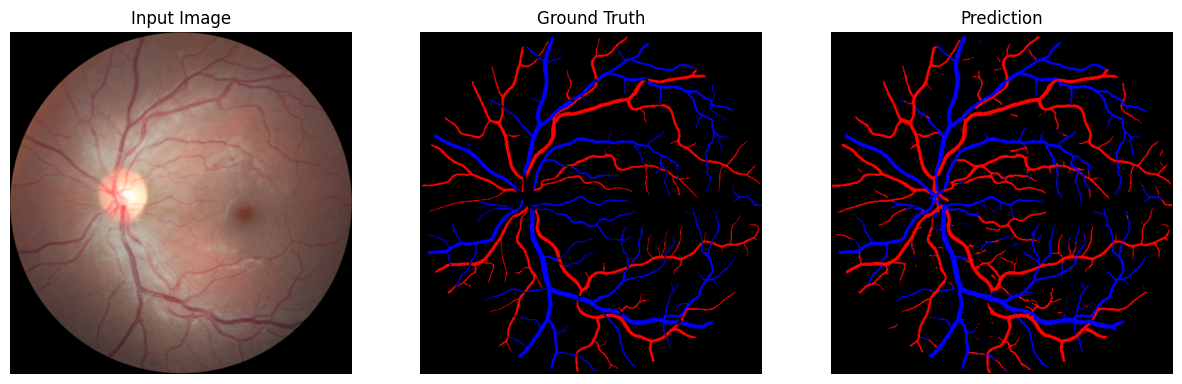

In [14]:
model.eval()
with torch.no_grad():
    print(f"{'Class':<15} {'Dice':>8}")
    print('-' * 25)

    all_class_dice = {c: [] for c in range(NUM_CLASSES)}

    for inputs, labels in test_dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model(inputs)
        preds  = torch.argmax(torch.softmax(logits, dim=1), dim=1)

        per_class, _ = dice_coef_per_class(preds, labels)
        for c, d in per_class.items():
            all_class_dice[c].append(d)

    for c in range(NUM_CLASSES):
        mean_d = np.mean(all_class_dice[c])
        print(f"  {CLASS_NAMES[c]:<13} {mean_d:>8.4f}")

    mean_vessel = np.mean([np.mean(all_class_dice[c]) for c in VESSEL_CLASSES])
    print(f"\n  Mean vessel Dice (artery + vein): {mean_vessel:.4f}")


def display_test_batch(model, dataloader):
    model.eval()
    inputs, labels = next(iter(dataloader))
    with torch.no_grad():
        logits = model(inputs.to(device))
        preds  = torch.argmax(torch.softmax(logits, dim=1), dim=1).cpu()

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(inputs[0].permute(1, 2, 0).clamp(0, 1))
    ax[0].set_title("Input Image")
    ax[1].imshow(class_to_rgb(labels[0].cpu().numpy()))
    ax[1].set_title("Ground Truth")
    ax[2].imshow(class_to_rgb(preds[0].numpy()))
    ax[2].set_title("Prediction")
    for a in ax:
        a.axis('off')
    plt.show()

display_test_batch(model, test_dataloader)
